# Sales Reporting 2019 — Mini project Python

**Mục tiêu:** phân tích doanh thu, số đơn theo giờ và các cặp sản phẩm mua cùng từ 12 file CSV.

Notebook dùng thư viện chuẩn Python để xử lý dữ liệu và Matplotlib để vẽ biểu đồ. Kết quả hiển thị trực tiếp trong notebook.

## 1. Đọc và kiểm tra dữ liệu
Kiểm tra đủ 12 file, cấu trúc cột, dòng trống, tiêu đề lặp, kiểu dữ liệu và địa chỉ. Các dòng hợp lệ được giữ để phân tích ở mục 2.

In [1]:
import csv
import re
from collections import Counter
from datetime import datetime
from decimal import Decimal, InvalidOperation
from pathlib import Path

FIELDS = ['Order ID', 'Product', 'Quantity Ordered', 'Price Each', 'Order Date', 'Purchase Address']
ADDRESS = re.compile(r'^.+,\s*([^,]+),\s*([A-Z]{2})\s+\d{5}(?:-\d{4})?$')


def load_sales(data_dir):
    filenames = [f'sales2019_{month}.csv' for month in range(1, 13)]
    if {p.name for p in data_dir.glob('sales2019_*.csv')} != set(filenames):
        raise ValueError('Cần đúng 12 file sales2019_1.csv đến sales2019_12.csv.')

    rows, checks = [], Counter()
    for filename in filenames:
        with (data_dir / filename).open(encoding='utf-8-sig', newline='') as stream:
            reader = csv.reader(stream)
            if next(reader, None) != FIELDS:
                raise ValueError(f'{filename}: cấu trúc cột không đúng.')

            for raw in reader:
                values = [value.strip() for value in raw]
                if not any(values):
                    checks['empty_row'] += 1
                    continue
                if len(values) != len(FIELDS) or not all(values):
                    checks['invalid_columns_or_missing_value'] += 1
                    continue
                if values == FIELDS:
                    checks['repeated_header'] += 1
                    continue

                order_id, product, qty_text, price_text, date_text, address = values
                try:
                    quantity = Decimal(qty_text)
                    price = Decimal(price_text)
                    order_date = datetime.strptime(date_text, '%m/%d/%y %H:%M')
                    if not order_id.isdigit() or not quantity.is_finite() or not price.is_finite():
                        raise ValueError
                    if quantity <= 0 or quantity != quantity.to_integral_value() or price <= 0:
                        raise ValueError
                    if price * 100 != (price * 100).to_integral_value():
                        raise ValueError
                except (InvalidOperation, ValueError):
                    checks['invalid_data_type_or_value'] += 1
                    continue

                location = ADDRESS.fullmatch(address)
                if not location:
                    checks['invalid_address'] += 1
                    continue

                rows.append(dict(order_id=order_id, product=product, quantity=int(quantity),
                                 price=price, order_date=order_date, purchase_address=address,
                                 city=location[1].strip(), state=location[2]))

    return rows, checks


rows, checks = load_sales(Path('data'))
print('Số file đã kiểm tra: 12')
print(f'Dòng hợp lệ: {len(rows):,}')
print(f'Dòng bị loại: {sum(checks.values()):,}')
for reason, count in sorted(checks.items()):
    print(f'  {reason}: {count:,}')

Số file đã kiểm tra: 12
Dòng hợp lệ: 185,950
Dòng bị loại: 900
  empty_row: 545
  repeated_header: 355


## 2. Xác định phạm vi và chỉ tiêu
Chọn các dòng năm 2019 theo ngày đặt hàng, tính doanh thu bằng cent nguyên và đếm đơn theo Order ID duy nhất. Sau đó tổng hợp theo tháng, thành phố, giờ, sản phẩm và cặp sản phẩm.

In [2]:
import itertools
from collections import defaultdict


def summarize(rows, year=2019):
    selected = [dict(r, sales_cents=r['quantity'] * int(r['price'] * 100),
                     month=r['order_date'].month, hour=r['order_date'].hour,
                     city=f"{r['city']} ({r['state']})")
                for r in rows if r['order_date'].year == year]
    if not selected:
        raise ValueError(f'Không có dữ liệu hợp lệ cho năm {year}.')
    orders = defaultdict(list)
    for row in selected:
        orders[row['order_id']].append(row)
    conflicts = [oid for oid, items in orders.items()
                 if len({(r['order_date'], r['purchase_address']) for r in items}) != 1]
    if conflicts:
        raise ValueError(f'Order ID có thời gian/địa chỉ mâu thuẫn: {conflicts[:5]}')
    def aggregate(key, domain=None):
        groups = defaultdict(list)
        for row in selected:
            groups[row[key]].append(row)
        return [dict(label=value, sales_cents=sum(r['sales_cents'] for r in groups[value]),
                     quantity=sum(r['quantity'] for r in groups[value]),
                     orders=len({r['order_id'] for r in groups[value]}),
                     line_items=len(groups[value])) for value in (domain if domain is not None else sorted(groups))]
    monthly = aggregate('month', range(1, 13))
    cities = sorted(aggregate('city'), key=lambda r: (-r['sales_cents'], r['label']))
    hourly = aggregate('hour', range(24))
    products = sorted(aggregate('product'), key=lambda r: (-r['quantity'], r['label']))
    pair_counts, product_orders = Counter(), Counter()
    for items in orders.values():
        basket = sorted({r['product'] for r in items})
        product_orders.update(basket)
        pair_counts.update(itertools.combinations(basket, 2))
    pairs = [dict(product_a=a, product_b=b, orders=count,
                  support=count / len(orders),
                  confidence_a_to_b=count / product_orders[a],
                  confidence_b_to_a=count / product_orders[b],
                  lift=count * len(orders) / (product_orders[a] * product_orders[b]))
             for (a, b), count in sorted(pair_counts.items(), key=lambda kv: (-kv[1], kv[0]))]
    total = sum(r['sales_cents'] for r in selected)
    for grouping in (monthly, cities, hourly, products):
        assert sum(r['sales_cents'] for r in grouping) == total
    assert sum(r['orders'] for r in hourly) == len(orders)
    assert sum(r['orders'] for r in monthly) == len(orders)
    return dict(year=year, sales_cents=total, valid_line_items=len(selected),
                orders=len(orders), quantity=sum(r['quantity'] for r in selected),
                excluded_other_year_rows=len(rows)-len(selected),
                aov_cents=total / len(orders), monthly=monthly, cities=cities,
                hourly=hourly, products=products, pairs=pairs)


summary = summarize(rows, year=2019)
print(f"Doanh thu: ${summary['sales_cents']/100:,.2f}")
print(f"Số đơn: {summary['orders']:,}")
print(f"Số lượng sản phẩm: {summary['quantity']:,}")
print(f"Dòng ngoài năm phân tích: {summary['excluded_other_year_rows']:,}")
assert sum(r['sales_cents'] for r in summary['monthly']) == summary['sales_cents']
assert sum(r['orders'] for r in summary['hourly']) == summary['orders']


Doanh thu: $34,483,365.68
Số đơn: 178,406
Số lượng sản phẩm: 209,038
Dòng ngoài năm phân tích: 34


## 3. Chuẩn bị biểu đồ
Dùng Matplotlib để vẽ trực tiếp từ các bảng tổng hợp đã tính ở trên.

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


def plot_bars(labels, values, *, title, unit, horizontal=False, money=False):
    height = max(4, 0.42 * len(labels) + 1.5) if horizontal else 4.5
    fig, ax = plt.subplots(figsize=(11, height), layout='constrained')
    formatter = StrMethodFormatter('${x:,.0f}' if money else '{x:,.0f}')

    if horizontal:
        ax.barh(labels, values, color='#087f8c')
        ax.invert_yaxis()
        ax.set_xlabel(unit)
        ax.xaxis.set_major_formatter(formatter)
        ax.grid(axis='x', alpha=0.2)
    else:
        ax.bar(labels, values, color='#087f8c')
        ax.set_ylabel(unit)
        ax.yaxis.set_major_formatter(formatter)
        ax.grid(axis='y', alpha=0.2)

    ax.set_title(title, loc='left', fontweight='bold')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()
    plt.close(fig)

## 4. Tháng nào có doanh thu cao nhất?
Lấy năm và tháng từ ngày đặt hàng để tránh gộp các ngày tháng 1/2020 vào tháng 1/2019.


Tháng 12: $4,613,443.34


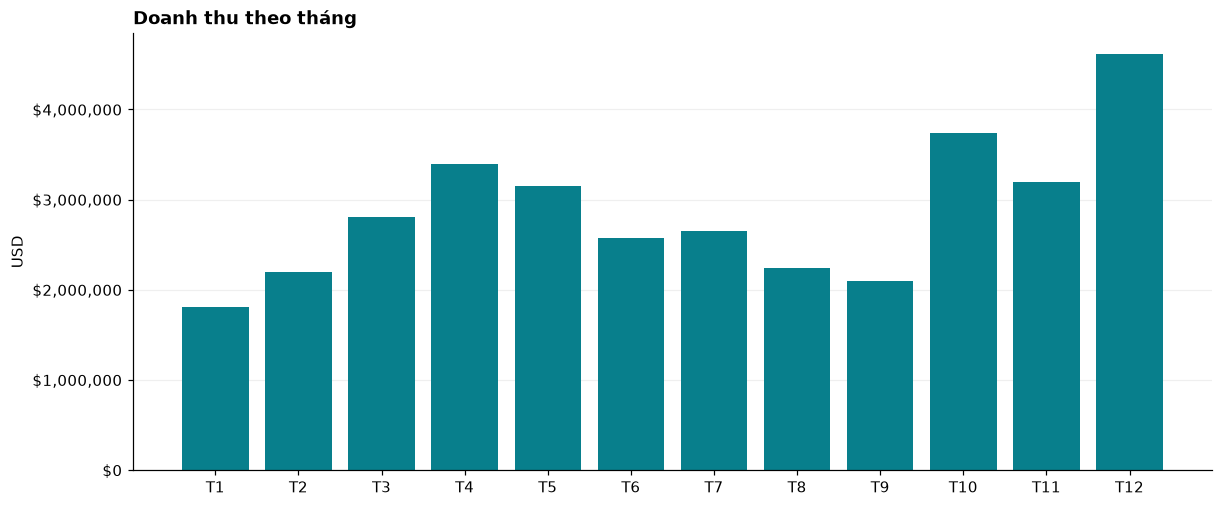

In [4]:
best = max(summary['monthly'], key=lambda r: r['sales_cents'])
print(f"Tháng {best['label']}: ${best['sales_cents']/100:,.2f}")

monthly = summary['monthly']
plot_bars([f"T{r['label']}" for r in monthly],
          [r['sales_cents'] / 100 for r in monthly],
          title='Doanh thu theo tháng', unit='USD', money=True)

## 5. Thành phố nào có doanh thu cao nhất?
Tách thành phố theo bang để giữ riêng Portland (OR) và Portland (ME). Doanh thu cao chưa có nghĩa thị trường có ROI cao.


San Francisco (CA) $8,259,719.03


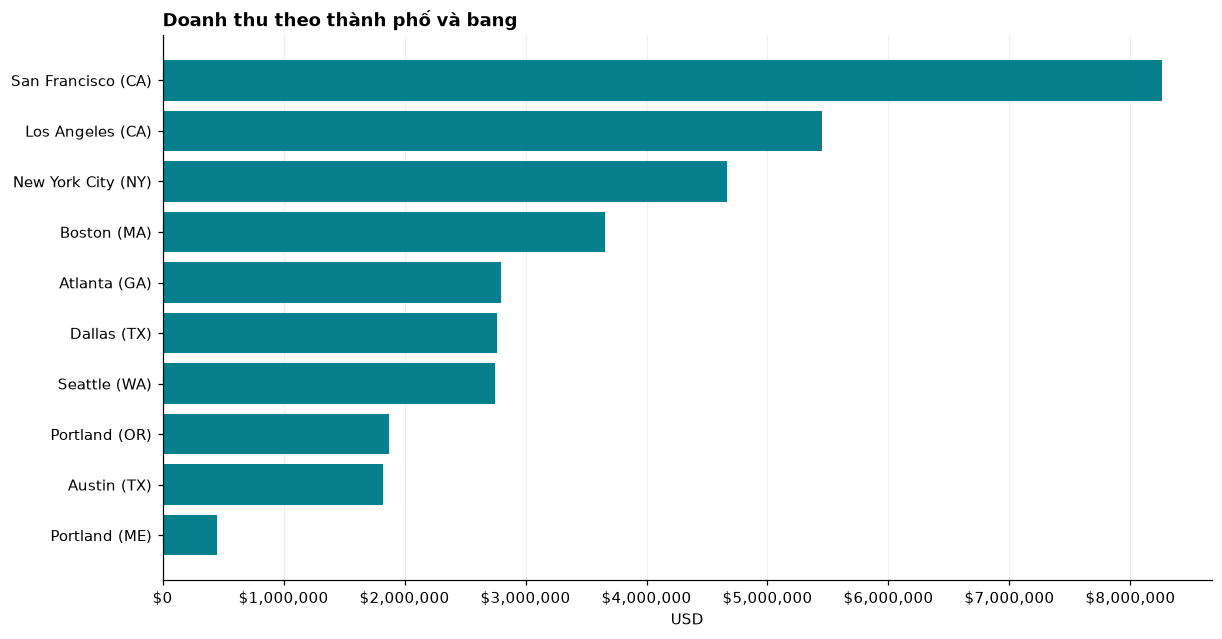

In [5]:
best = summary['cities'][0]
print(best['label'], f"${best['sales_cents']/100:,.2f}")

cities = summary['cities']
plot_bars([r['label'] for r in cities], [r['sales_cents'] / 100 for r in cities],
          title='Doanh thu theo thành phố và bang', unit='USD', horizontal=True, money=True)

## 6. Giờ nào có nhiều đơn nhất?
Đếm đơn duy nhất theo giờ đặt hàng, không đếm dòng sản phẩm. Dữ liệu không có múi giờ hoặc kết quả quảng cáo.

19:00 — 12,377 đơn
12:00 — 12,082 đơn
11:00 — 11,882 đơn


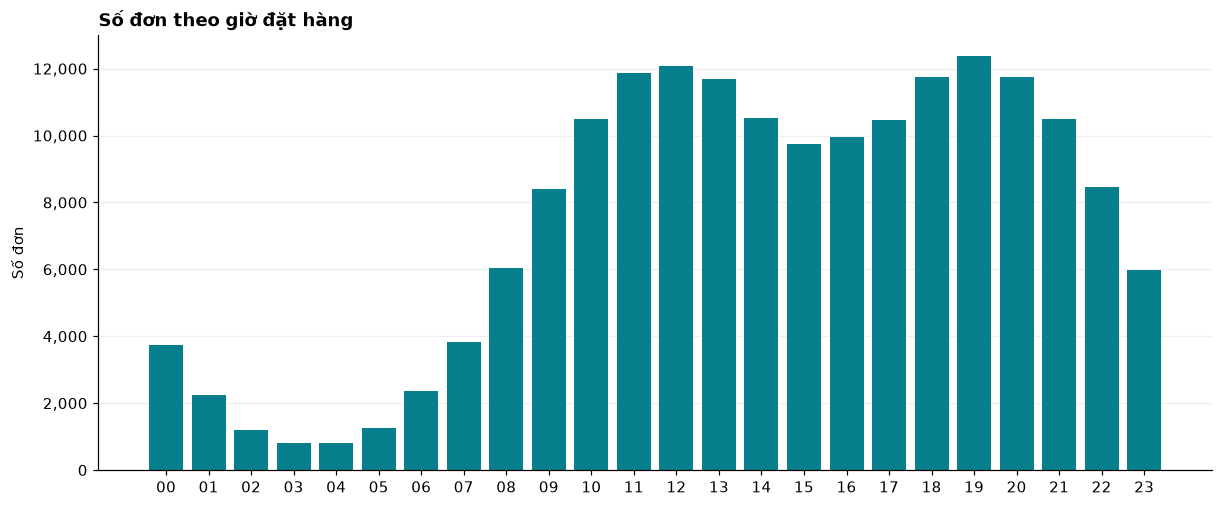

In [6]:
for row in sorted(summary['hourly'], key=lambda r: (-r['orders'], r['label']))[:3]:
    print(f"{row['label']:02d}:00 — {row['orders']:,} đơn")

hourly = summary['hourly']
plot_bars([f"{r['label']:02d}" for r in hourly], [r['orders'] for r in hourly],
          title='Số đơn theo giờ đặt hàng', unit='Số đơn')

## 7. Sản phẩm nào thường được mua cùng?
Mỗi cặp được tính tối đa một lần trong một đơn hàng. Biểu đồ hiển thị 10 cặp có nhiều đơn nhất.

Lightning Charging Cable + iPhone | 1010 đơn | support 0.57% | lift 1.22
Google Phone + USB-C Charging Cable | 997 đơn | support 0.56% | lift 1.47
Wired Headphones + iPhone | 462 đơn | support 0.26% | lift 0.64
Google Phone + Wired Headphones | 422 đơn | support 0.24% | lift 0.72
Apple Airpods Headphones + iPhone | 372 đơn | support 0.21% | lift 0.63


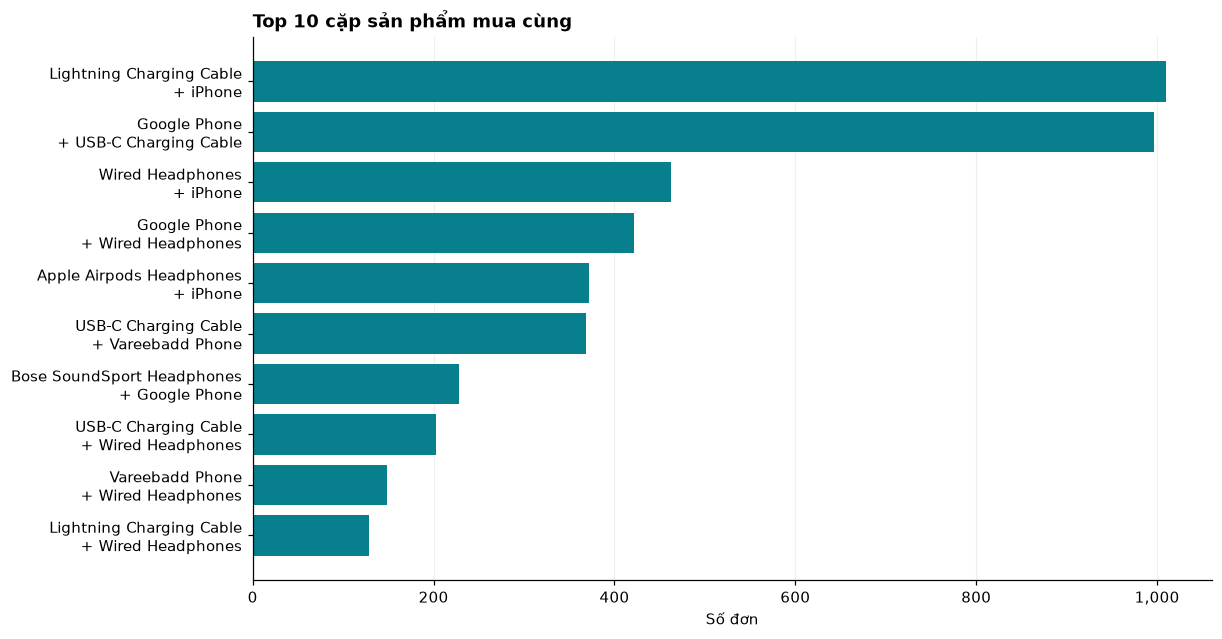

In [7]:
for row in summary['pairs'][:5]:
    print(row['product_a'], '+', row['product_b'], '|', row['orders'], 'đơn',
          '| support', f"{row['support']:.2%}", '| lift', f"{row['lift']:.2f}")

pairs = summary['pairs'][:10]
if pairs:
    labels = [f"{r['product_a']}\n+ {r['product_b']}" for r in pairs]
    plot_bars(labels, [r['orders'] for r in pairs],
              title='Top 10 cặp sản phẩm mua cùng', unit='Số đơn', horizontal=True)
else:
    print('Không có cặp sản phẩm mua cùng.')

## 8. Sản phẩm nào bán được nhiều nhất?
Xếp theo số lượng sản phẩm bán được, không xếp theo doanh thu.

AAA Batteries (4-pack) | 31,012 sản phẩm
AA Batteries (4-pack) | 27,635 sản phẩm
USB-C Charging Cable | 23,971 sản phẩm
Lightning Charging Cable | 23,211 sản phẩm
Wired Headphones | 20,553 sản phẩm


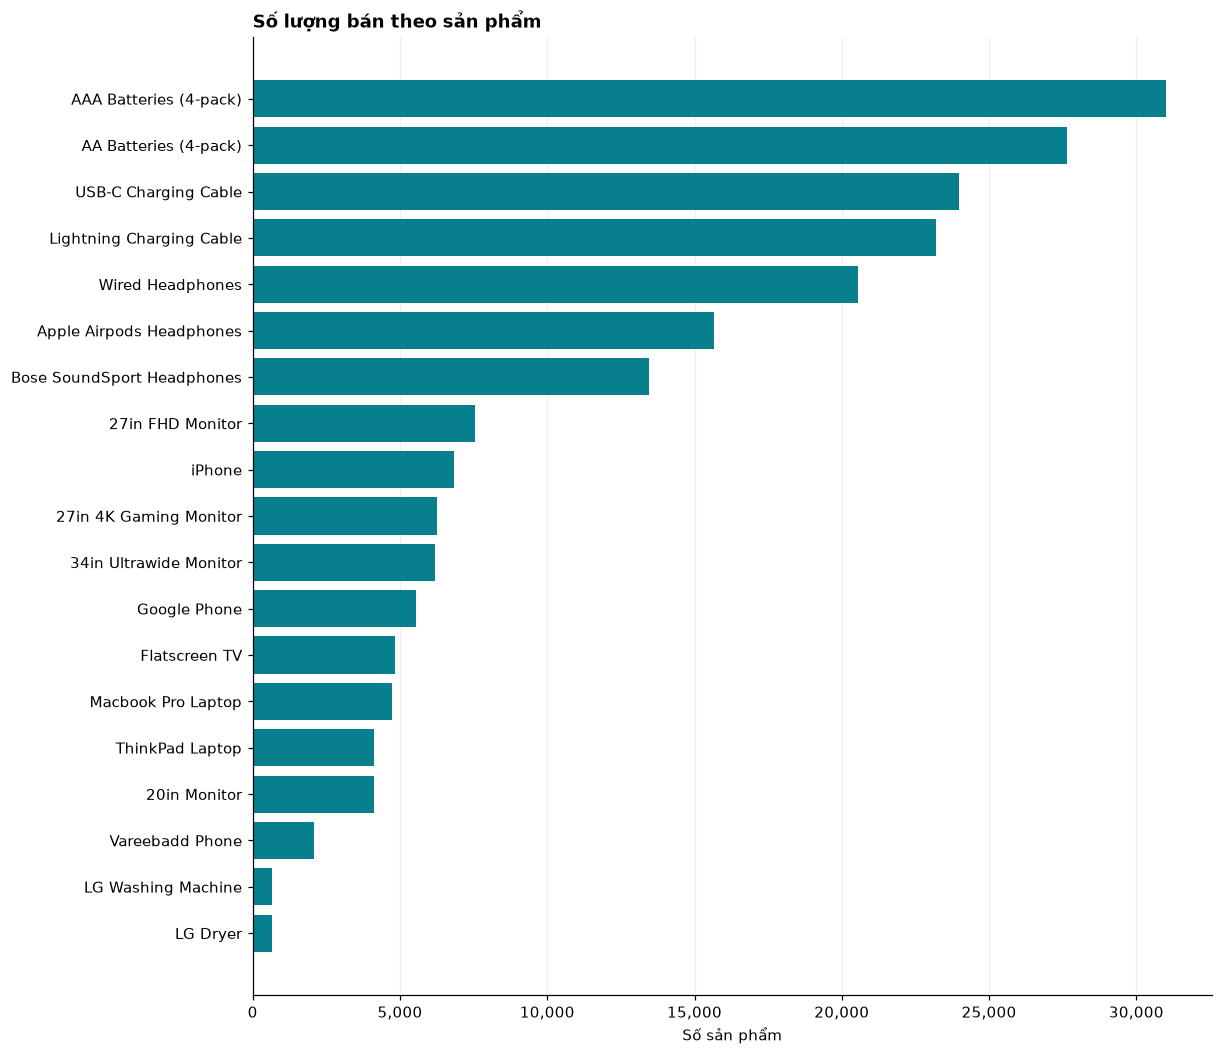

In [8]:
for row in summary['products'][:5]:
    print(row['label'], '|', f"{row['quantity']:,}", 'sản phẩm')

products = summary['products']
plot_bars([r['label'] for r in products], [r['quantity'] for r in products],
          title='Số lượng bán theo sản phẩm', unit='Số sản phẩm', horizontal=True)